In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F
from datasets import load_dataset
import matplotlib.pyplot as plt
import math

# 1. Load the dataset (streaming or small slice for fast local training)
dataset = load_dataset("roneneldan/TinyStories", split="train[:2000]")

print(f"Total loaded stories: {len(dataset)}")
for i in range(2):
    print(f"\n--- Story {i+1} (Length: {len(dataset[i]['text'])} chars) ---")
    print(dataset[i]['text'][:300] + "...")

# Combine subset into one text corpus
text = "\n\n".join([item['text'] for item in dataset])
print(f"\nTotal characters in corpus: {len(text):,}")

# 2. Preprocess the text (Character-level tokenizer)
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(f"Vocabulary size: {vocab_size} unique characters")

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

# Encode entire dataset and split 90% train / 10% validation
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

# 3. Preparing training data (Next-token prediction batches)
batch_size = 32
block_size = 64  # Context window length
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i+block_size] for i in ix])
    y = torch.stack([d[i+1:i+block_size+1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch('train')
print("Sample input shape:", xb.shape, "| Target shape:", yb.shape)


c:\Users\markg\PUSL3205-Large-Language-Models-and-Generative-AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\markg\PUSL3205-Large-Language-Models-and-Generative-AI\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\markg\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an adm

Total loaded stories: 2000

--- Story 1 (Length: 701 chars) ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and ...

--- Story 2 (Length: 705 chars) ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Bee...

Total characters in corpus: 1,704,918
Vocabulary size: 80 unique characters
Using device: cpu
Sample input shape: torch.Size([32, 64]) | Target shape: torch.Size([32, 64])


In [2]:
# Hyperparameters (Baseline Tiny Transformer)
n_embd = 128
n_head = 4
n_layer = 3
dropout = 0.1

# 4. Build the Transformer architecture
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(head_size * num_heads, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # Residual connection + LayerNorm
        x = x + self.ffwd(self.ln2(x))   # Residual connection + LayerNorm
        return x

class TinyTransformerLM(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

# 5. Initialize the model and AdamW optimizer
model = TinyTransformerLM().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
print(f"Model initialized with {sum(p.numel() for p in model.parameters()):,} parameters.")


Model initialized with 622,672 parameters.


Step    0 | Train Loss: 4.5403 | Val Loss: 4.5303
Step  300 | Train Loss: 2.2741 | Val Loss: 2.3123
Step  600 | Train Loss: 2.0226 | Val Loss: 2.0642
Step  900 | Train Loss: 1.8018 | Val Loss: 1.8511
Step 1200 | Train Loss: 1.6679 | Val Loss: 1.7182
Step 1500 | Train Loss: 1.5781 | Val Loss: 1.6210


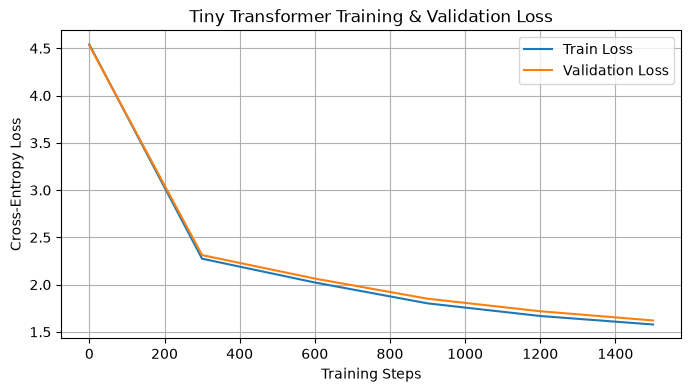


Final Validation Loss: 1.6210
Validation Perplexity: 5.06

--- Generated Story ---
Once upon a time thed thenut bick. His fus mused they pon to It to graK bece of and offing, buse clooled to said and play- and thand and friend in, gin! Lily bee excited came otse it with al but onn't bitte big was feella."quop nerseed unjused in turt stoblecide so,


In [3]:
max_iters = 1500
eval_interval = 300
eval_iters = 50

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

# 6 & 7. Train the model and monitor loss
steps, train_losses, val_losses = [], [], []

for iter in range(max_iters + 1):
    if iter % eval_interval == 0:
        losses = estimate_loss()
        steps.append(iter)
        train_losses.append(losses['train'])
        val_losses.append(losses['val'])
        print(f"Step {iter:4d} | Train Loss: {losses['train']:.4f} | Val Loss: {losses['val']:.4f}")

    xb, yb = get_batch('train')
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# Plot and save loss curves to results/
plt.figure(figsize=(8, 4))
plt.plot(steps, train_losses, label='Train Loss')
plt.plot(steps, val_losses, label='Validation Loss')
plt.xlabel('Training Steps')
plt.ylabel('Cross-Entropy Loss')
plt.title('Tiny Transformer Training & Validation Loss')
plt.legend()
plt.grid(True)
plt.savefig('../results/loss_curve.png', bbox_inches='tight')
plt.show()

# 8. Evaluate validation loss & perplexity
final_val_loss = val_losses[-1]
perplexity = math.exp(final_val_loss)
print(f"\nFinal Validation Loss: {final_val_loss:.4f}")
print(f"Validation Perplexity: {perplexity:.2f}")

# 9. Generate stories from prompt
prompt = "Once upon a time"
context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
generated_tokens = model.generate(context, max_new_tokens=250)[0].tolist()
print("\n--- Generated Story ---")
print(decode(generated_tokens))


In [4]:
# 11. Save the trained model parameters and configuration
checkpoint = {
    'model_state_dict': model.state_dict(),
    'config': {'vocab_size': vocab_size, 'n_embd': n_embd, 'n_head': n_head, 'n_layer': n_layer, 'block_size': block_size},
    'stoi': stoi,
    'itos': itos
}
torch.save(checkpoint, '../results/tiny_transformer.pt')
print("Saved model checkpoint to results/tiny_transformer.pt")


Saved model checkpoint to results/tiny_transformer.pt
